# 142 · laser-count ablation
decres-rescale-aug10-v1 retrained with only K of the 100 lasers (K = 80, 60, 40, 20, 10, 5, 1), three ways to pick them:
- **random**: uniform random subset (seed K)
- **importance**: the K lasers with the largest mean train ΔIoU when dropped (nb140 cache, decres-rescale-aug10-v1)
- **grid**: a regular r×c lattice as even as possible (K = 5: 2×2 + centre, K = 1: centre)

Everything else = decres-rescale-aug10-v1 (same args, seed 42 → same init and data order; `--lasers` adds a non-persistent buffer only).
The dropped lasers are never seen: the model slices them out before the per-sample z-score and freq stage and masks them in the laser stage, at train and eval.
Train: `scripts/laser_ablation.sh` (tmux `lasers`), subsets `scripts/laser_subsets.py` → `runs/laser_ablation/subsets.json`.
Metric: pooled per-sample iou08 over the ID / OOD eval splits (`metrics/eval/{id,ood}/iou08`, eager eval, last eval of the run).

In [1]:
import json, re, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "notebooks/out"
S = json.load(open(ROOT / "runs/laser_ablation/subsets.json"))
KS = [80, 60, 40, 20, 10, 5, 1]
STRATS = ["random", "importance", "grid"]
COL = {"random": "#7f7f7f", "importance": "#d62728", "grid": "#1f77b4"}
BASE = "decres-rescale-aug10-v1"
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})

In [2]:
def last_metrics(run):
    # last logged pooled ID / OOD iou08 of a run (logs-rank0.txt), the batch it was logged at, and whether the run finished (ep300 checkpoint)
    f = ROOT / f"runs/{run}/logs-rank0.txt"
    if not f.exists(): return dict(id=np.nan, ood=np.nan, batch=0, done=False)
    r = dict(id=np.nan, ood=np.nan, batch=0)
    for m in re.finditer(r"\[metric\]\[batch=(\d+)\]: metrics/eval/(id|ood)/iou08: ([0-9.]+)", f.read_text()):
        r[m[2]], r["batch"] = float(m[3]), int(m[1])
    r["done"] = (ROOT / f"runs/{run}/checkpoints/ep300-ba3000-rank0.pt").exists()
    return r

R = {(s, k): last_metrics(f"lasers-{s}-{k}-v1") for s in STRATS for k in KS}
for s in STRATS: R[(s, 100)] = last_metrics(BASE)
print(f"{'run':28s} {'ID':>6s} {'OOD':>6s}  batch  done")
for (s, k), r in sorted(R.items(), key=lambda t: (t[0][0], -t[0][1])):
    if k < 100 or s == "random": print(f"{(BASE if k == 100 else f'lasers-{s}-{k}-v1'):28s} {r['id']:6.3f} {r['ood']:6.3f} {r['batch']:6d}  {r['done']}")

run                              ID    OOD  batch  done
lasers-grid-80-v1               nan    nan      0  False
lasers-grid-60-v1               nan    nan      0  False
lasers-grid-40-v1             0.699  0.381   2500  False
lasers-grid-20-v1             0.691  0.378   3000  True
lasers-grid-10-v1             0.686  0.371   3000  True
lasers-grid-5-v1              0.667  0.372   3000  True
lasers-grid-1-v1              0.592  0.334   3000  True
lasers-importance-80-v1         nan    nan      0  False
lasers-importance-60-v1         nan    nan      0  False
lasers-importance-40-v1         nan    nan      0  False
lasers-importance-20-v1       0.694  0.380   3000  True
lasers-importance-10-v1       0.683  0.373   3000  True
lasers-importance-5-v1        0.666  0.371   3000  True
lasers-importance-1-v1        0.595  0.332   3000  True
decres-rescale-aug10-v1       0.709  0.382   3000  True
lasers-random-80-v1             nan    nan      0  False
lasers-random-60-v1             nan    na

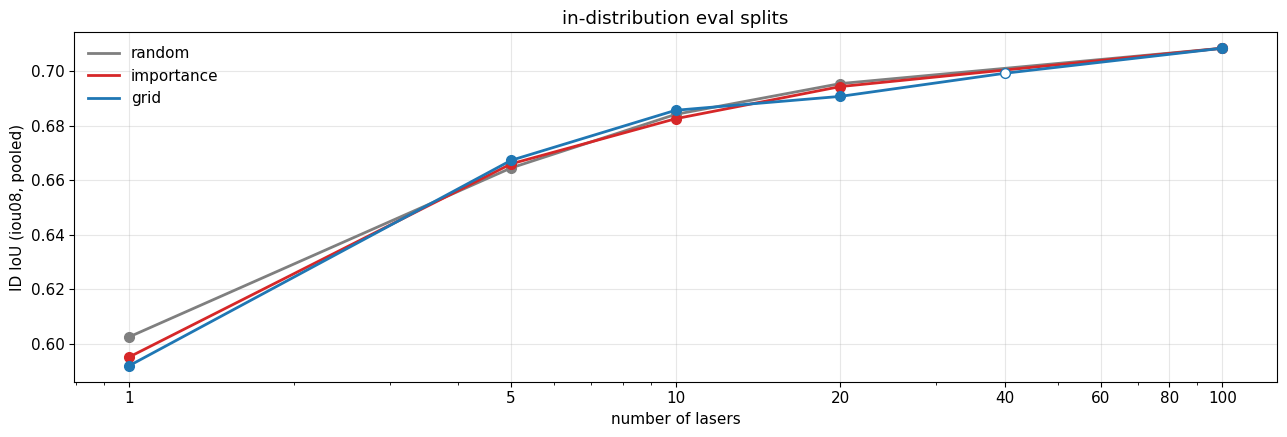

In [3]:
def plot(key, title):
    # x = number of lasers (log), y = pooled iou08; filled = finished run, hollow = still training (last eval so far)
    fig, ax = plt.subplots(figsize=(13, 4.5))
    for s in STRATS:
        ks = [k for k in [100] + KS if not np.isnan(R[(s, k)][key])]
        y = [R[(s, k)][key] for k in ks]
        ax.plot(ks, y, "-", color=COL[s], label=s, lw=2)
        for k, v in zip(ks, y):
            ax.plot(k, v, "o", ms=7, color=COL[s], mfc=COL[s] if R[(s, k)]["done"] else "white")
    ax.set_xscale("log")
    ax.set_xticks([1, 5, 10, 20, 40, 60, 80, 100], ["1", "5", "10", "20", "40", "60", "80", "100"])
    ax.set_xlabel("number of lasers")
    ax.set_ylabel(f"{key.upper()} IoU (iou08, pooled)")
    ax.set_title(title)
    ax.grid(alpha=.3)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(OUT / f"142_lasers_{key}.svg")
    plt.show()

plot("id", "in-distribution eval splits")

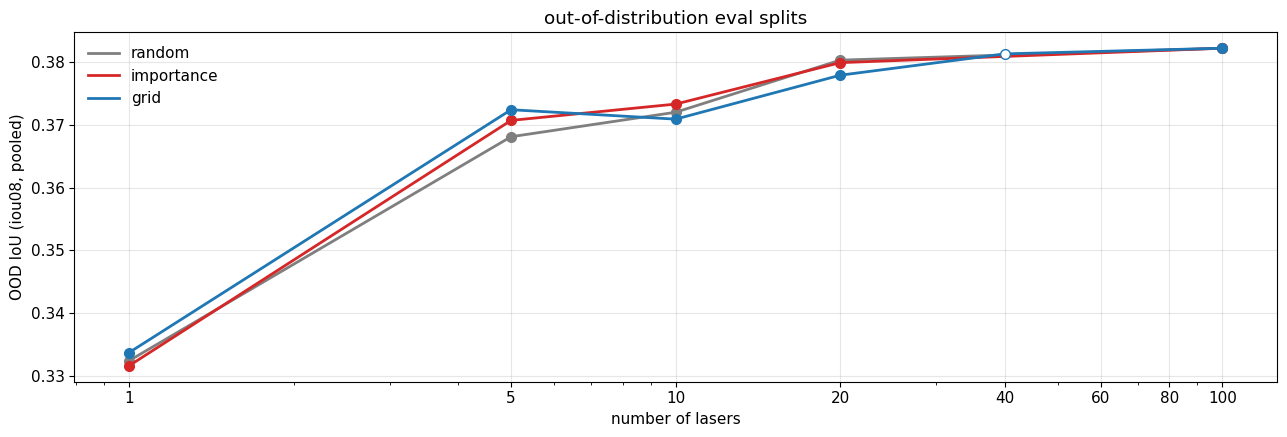

In [4]:
plot("ood", "out-of-distribution eval splits")

## the lasers each run trains on
Filled = kept laser; row 0 of the 10×10 grid at the top (laser id = row·10 + col). Importance row: colour = mean train ΔIoU of that laser.

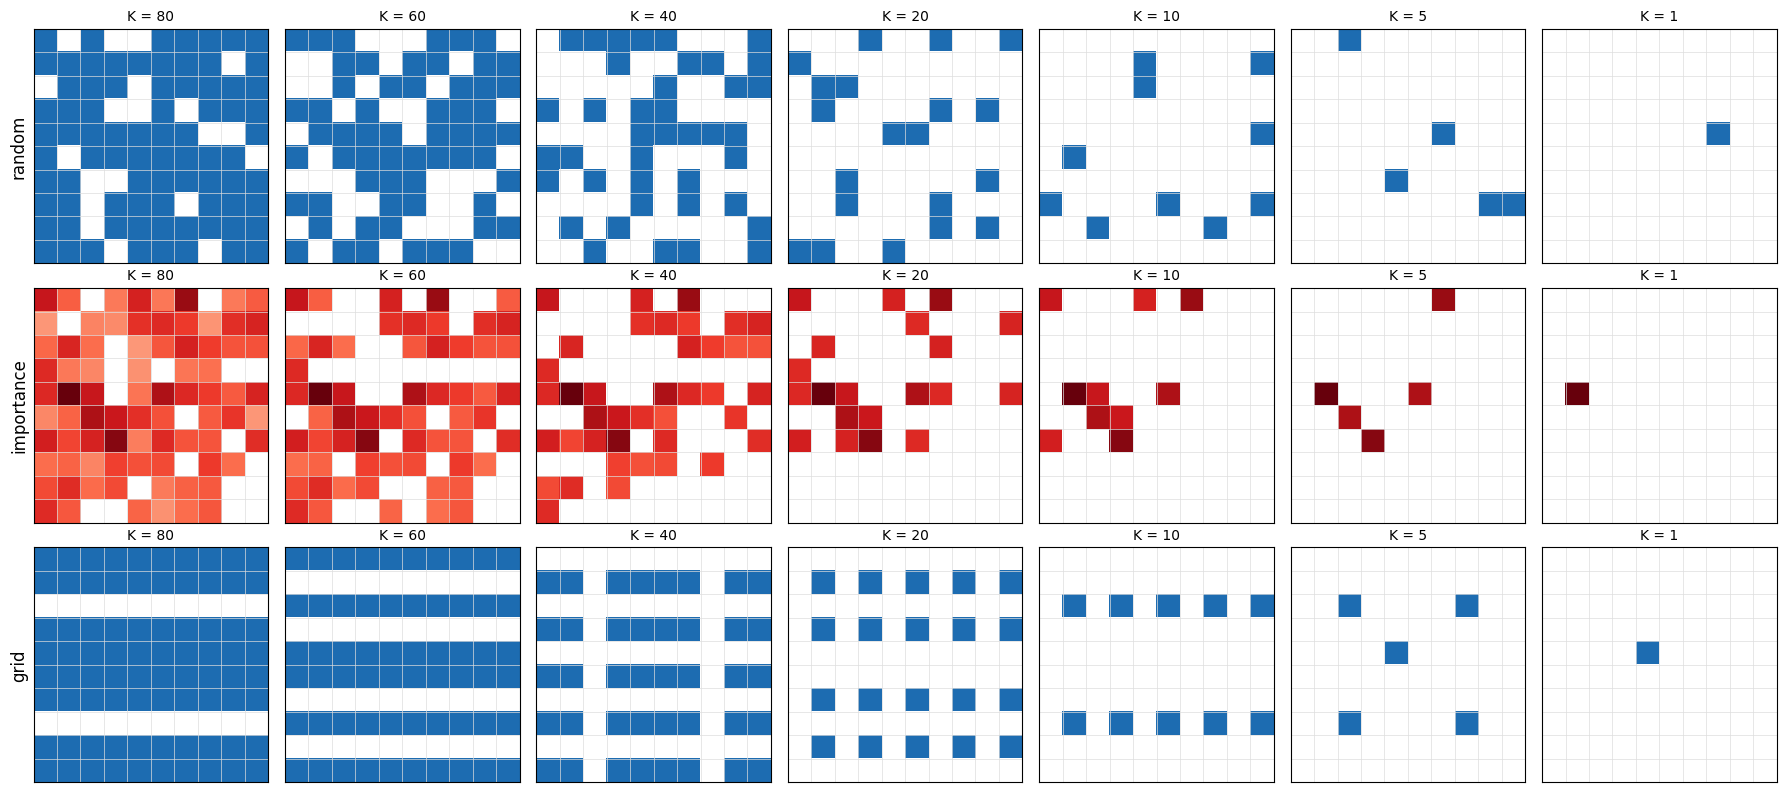

In [5]:
imp = np.array(S["importance_score"]).reshape(10, 10)
fig, axs = plt.subplots(3, len(KS), figsize=(18, 8))
for i, s in enumerate(STRATS):
    for j, k in enumerate(KS):
        ax = axs[i, j]
        g = np.zeros(100); g[S[s][str(k)]] = 1
        g = g.reshape(10, 10)
        if s == "importance": ax.imshow(np.where(g > 0, imp, np.nan), cmap="Reds", vmin=0, vmax=imp.max())
        else: ax.imshow(np.where(g > 0, 1, np.nan), cmap="Blues", vmin=0, vmax=1.3)
        ax.set_xticks(np.arange(-.5, 10), minor=True)
        ax.set_yticks(np.arange(-.5, 10), minor=True)
        ax.grid(which="minor", color="#ddd", lw=.5)
        ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
        ax.set_title(f"K = {k}", fontsize=10)
        if j == 0: ax.set_ylabel(s, fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "142_lasers_subsets.svg")
plt.show()